Task 1 

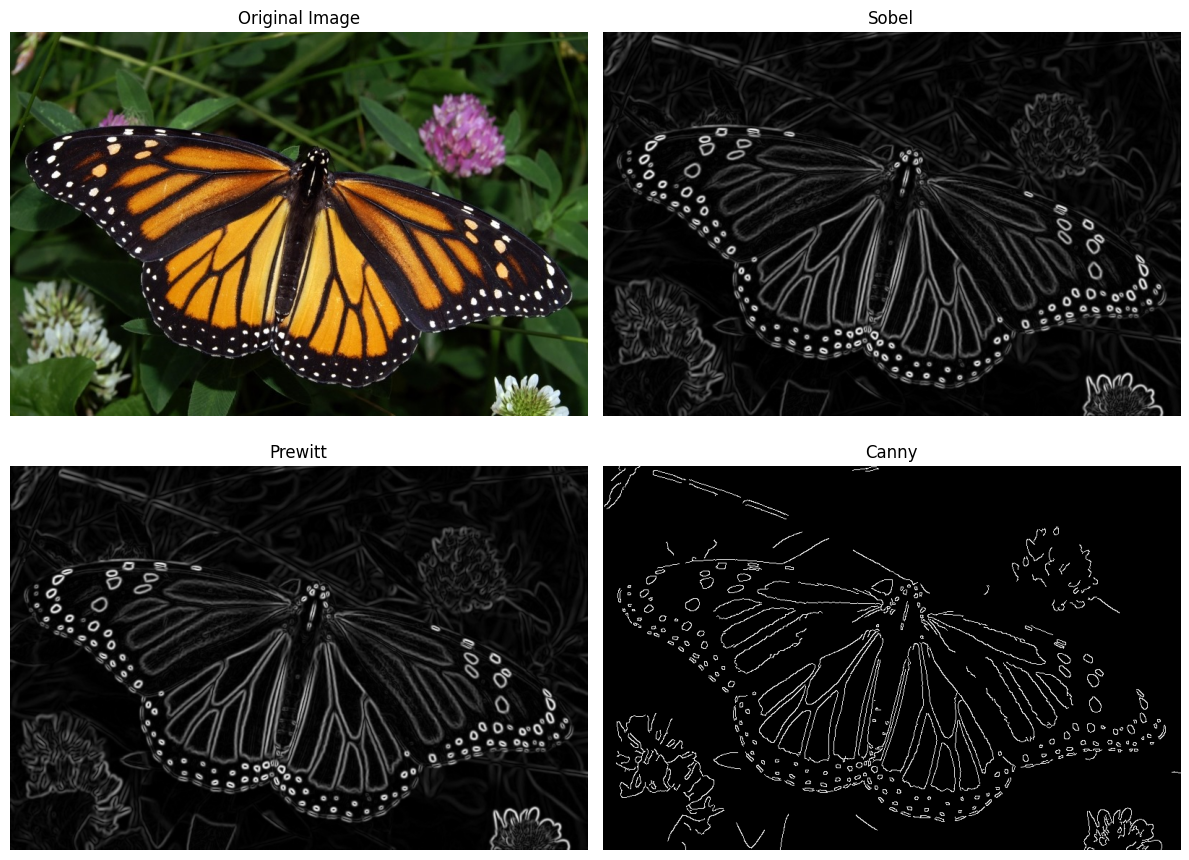

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

imgFile = r"C:\Users\M\Desktop\img\lab-8\Butterfly.jpg"

img = cv2.imread(imgFile)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
blurred = cv2.GaussianBlur(gray, (5, 5), 0)

# Sobel
sobel_x = cv2.Sobel(blurred, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(blurred, cv2.CV_64F, 0, 1, ksize=3)
sobel_magnitude = cv2.magnitude(sobel_x, sobel_y)

sobel_edges = cv2.normalize(
    sobel_magnitude, None, 0, 255, cv2.NORM_MINMAX
).astype(np.uint8)

# Prewitt
kernel_x = np.array([
    [-1, 0, 1],
    [-1, 0, 1],
    [-1, 0, 1]
], dtype=np.float64)

kernel_y = np.array([
    [-1, -1, -1],
    [0, 0, 0],
    [1, 1, 1]
], dtype=np.float64)

prewitt_x = cv2.filter2D(blurred, cv2.CV_64F, kernel_x)
prewitt_y = cv2.filter2D(blurred, cv2.CV_64F, kernel_y)
prewitt_magnitude = cv2.magnitude(prewitt_x, prewitt_y)

prewitt_edges = cv2.normalize(
    prewitt_magnitude, None, 0, 255, cv2.NORM_MINMAX
).astype(np.uint8)

# Canny
canny_edges = cv2.Canny(blurred, 100, 200)

# Display results
plt.figure(figsize=(12, 9))

plt.subplot(2, 2, 1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(sobel_edges, cmap="gray")
plt.title("Sobel")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(prewitt_edges, cmap="gray")
plt.title("Prewitt")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(canny_edges, cmap="gray")
plt.title("Canny")
plt.axis("off")

plt.tight_layout()
plt.show()

Task 2 

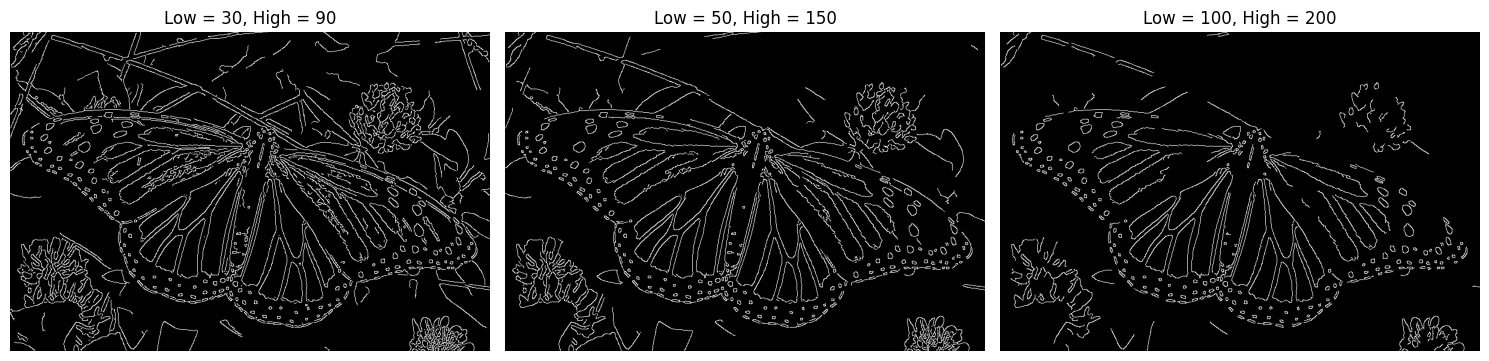

In [3]:
# Uses the blurred grayscale image from Task 1.

canny_30_90 = cv2.Canny(blurred, 30, 90)
canny_50_150 = cv2.Canny(blurred, 50, 150)
canny_100_200 = cv2.Canny(blurred, 100, 200)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(canny_30_90, cmap="gray")
plt.title("Low = 30, High = 90")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(canny_50_150, cmap="gray")
plt.title("Low = 50, High = 150")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(canny_100_200, cmap="gray")
plt.title("Low = 100, High = 200")
plt.axis("off")

plt.tight_layout()
plt.show()

Effect of Canny Thresholds

With 30 and 90, more edges can be detected, including small details in the butterfly and background. This can make the image look busy.

With 50 and 150, some weaker edges are removed, giving a cleaner result while keeping many details.

With 100 and 200, the stronger edges stand out, but some small details may be lost.

Overall, lower thresholds show more detail, while higher thresholds usually produce fewer edges and a cleaner image.